# Module 12 · Model comparison, validation, and sensitivity analysis
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **When two stochastic models disagree, what evidence supports choosing one—and how fragile is that choice?**

Guided work: about 45–55 minutes. Investigations: about 25–35 minutes. This is **Concept Lab 6, Part B (week 12)**. Submit Parts A and B from Modules 11 and 12 together as **one submission due in week 12**. Improve the existing sustained project; no additional project is assigned.

[Course home](../index.html) · [Interactive lesson](../modules/module12.html) · [Project guide](../project-guide.html)

This lab compares one-day predictions of observed daily bike rentals. It separates chronological selection, predictive assessment, uncertainty calibration, and assumption sensitivity. A synthetic scoring check and a deliberately invalid leakage experiment are explicitly labeled.

## 1. Define the target and information before comparing scores
Let $C_t$ be the observed count on day $t$. At the end of day $t-1$, the available information is $\mathcal F_{t-1}=\sigma(C_0,\ldots,C_{t-1})$. A legitimate one-day predictive distribution $F_t$ and point forecast $\widehat C_t$ can depend on this information, not on $C_t$ or later outcomes.

Use **January–June (181 days)** as initial history, **July–August (62 targets)** to select between two prespecified GP length scales by one-day MAE, then **September–December (122 targets)** for a declared assessment. Freeze the selected length scale before computing assessment scores. Each later origin may update the rolling conditioning window and its mean/scale with counts that have since become observed. This is not Module 11’s fixed August 31 origin, which supplied no later observations to any forecast.

The whole 2011 sample, including September–December, has been inspected in earlier modules. This is a **reused development assessment**, not a newly untouched final holdout. Model selection, assessment, and sensitivity are distinct purposes even when transparent data reuse limits the conclusions.

Before running: if September 10’s outcome changes, which September forecasts are allowed to change? Would randomly shuffling dates preserve the one-day information set?

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.linalg import cho_factor, cho_solve
from scipy.stats import norm
from IPython.display import display
SEED, JITTER, ALPHA = 6231, 1e-10, 0.2
Z80 = norm.ppf(1-ALPHA/2)
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

### Observed data and provenance
The unchanged [UCI Bike Sharing sample](https://doi.org/10.24432/C5W894), Fanaee-T (2013), CC BY 4.0, contains **365 system-wide daily completed-rental totals for 2011**. These are observed counts; latent demand, unmet demand, station inventory, and independent sensor errors are not observed. Verify the bundled checksum and exact chronology before fitting. No rows are removed or fabricated.

In [2]:
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p/"data/bike_daily_2011.csv").is_file())
data_path = ROOT/"data/bike_daily_2011.csv"
source = json.loads((ROOT/"data/source_metadata.json").read_text())
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(data_path, parse_dates=["dteday"])
assert bike.dteday.tolist() == list(pd.date_range("2011-01-01", "2011-12-31"))
assert bike.dteday.is_unique and bike.cnt.ge(0).all()
assert np.all(bike.cnt == np.floor(bike.cnt))
counts = bike.cnt.to_numpy(float)
selection_days, assessment_days = np.arange(181, 243), np.arange(243, 365)
assert [counts[:181].sum(), counts[181:243].sum(), counts[243:].sum()] == [524652, 278032, 440419]
assert bike.dteday.iloc[181] == pd.Timestamp("2011-07-01")
assert bike.dteday.iloc[243] == pd.Timestamp("2011-09-01")
print("Verified: 181 initial-history days, 62 selection targets, 122 reused assessment targets.")

Verified: 181 initial-history days, 62 selection targets, 122 reused assessment targets.


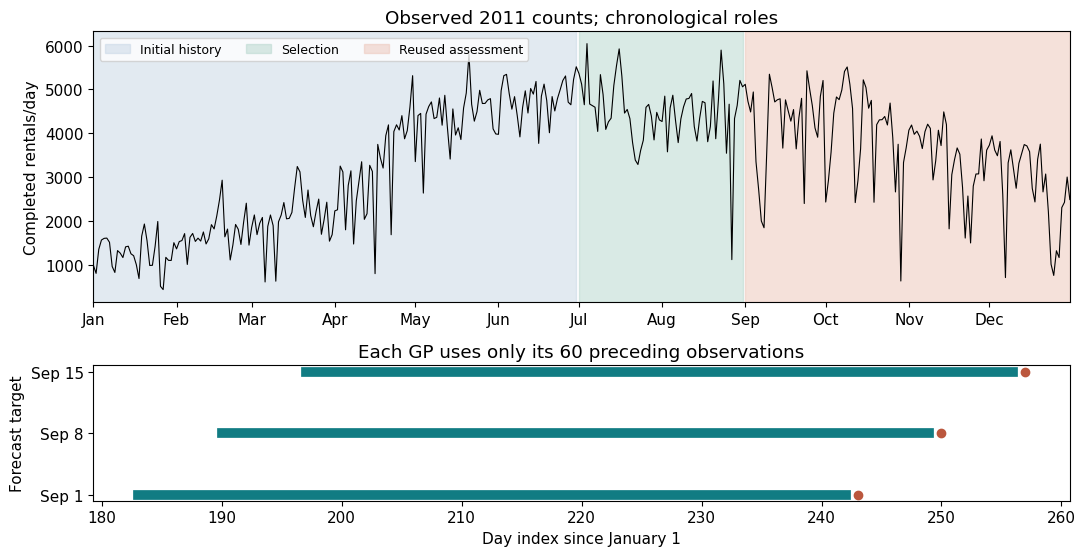

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.7), gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(bike.dteday, counts, color="black", linewidth=0.8)
for start, stop, color, label in [(0, 180, "#c6d6e5", "Initial history"), (181, 242, "#b5d6cc", "Selection"), (243, 364, "#edc4b7", "Reused assessment")]:
    axes[0].axvspan(bike.dteday.iloc[start], bike.dteday.iloc[stop], color=color, alpha=0.5, label=label)
axes[0].set(ylabel="Completed rentals/day", title="Observed 2011 counts; chronological roles")
axes[0].set_xlim(bike.dteday.iloc[0], bike.dteday.iloc[-1]); axes[0].legend(ncol=3, fontsize=9); axes[0].xaxis.set_major_locator(mdates.MonthLocator()); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for row, target in enumerate([243, 250, 257]):
    axes[1].plot([target-60, target-1], [row, row], linewidth=7, color="#117c83")
    axes[1].plot(target, row, "o", color="#bb573d")
axes[1].set(yticks=[0, 1, 2], yticklabels=["Sep 1", "Sep 8", "Sep 15"], xlabel="Day index since January 1", ylabel="Forecast target", title="Each GP uses only its 60 preceding observations")
fig.tight_layout(); plt.show()

## 2. Prespecify models and issue honest rolling predictions
For the GP, fit $\bar c_t$ and $s_t$ (ddof=0) from the **60 counts before each target**, and standardize that window. Use a zero-mean standardized RBF prior with amplitude 1, length $\ell\in\{14,45\}$ days, and assumed observation-noise SD 0.5. These candidates and the 60-day window are declared in advance, not optimized using assessment outcomes.

Relative window inputs $0,\ldots,59$ and next input 60 have the same covariance geometry at every origin:
$$K_{ij}=\exp[-(i-j)^2/(2\ell^2)],\quad k_i=\exp[-(60-i)^2/(2\ell^2)],\quad A=K+(0.5^2+\delta)I,$$
$$w=A^{-1}k,\quad \mu_t=\bar c_t+w^T(c_{t-60:t-1}-\bar c_t\mathbf1),\quad
\sigma_t^2=s_t^2(1+0.5^2-k^Tw),\quad\delta=10^{-10}.$$
Compute $w$ once per candidate using a Cholesky solve; window values, mean, and scale update at each origin. The final variance is for a **new observation**, not the latent curve. Jitter stabilizes the training solve and is not future observation noise. All bands condition on these assumptions and plug-in estimates.

In [4]:
def gp_rule(ell):
    x = np.arange(60.)
    K = np.exp(-0.5*((x[:, None]-x)/ell)**2)
    k = np.exp(-0.5*((60-x)/ell)**2)
    factor = cho_factor(K+(0.5**2+JITTER)*np.eye(60), lower=True)
    weights = cho_solve(factor, k)
    return weights, 1+0.5**2-k@weights
rules = {ell: gp_rule(ell) for ell in [14, 45]}
def gp_forecast(prefix, ell):
    history = np.asarray(prefix[-60:], float)
    center, scale = history.mean(), history.std(ddof=0)
    if len(history) != 60 or scale <= 0: raise ValueError("Need 60 nonconstant past counts")
    weights, variance = rules[ell]
    return center+weights@(history-center), scale*np.sqrt(variance)

Two simple point baselines are persistence $\mu_t=C_{t-1}$ and weekly lag-seven $\mu_t=C_{t-7}$. To compare probabilistic forecasts, explicitly add a Gaussian residual model for each baseline. Use the **60 previously available errors**, with no demeaning:
$$e_j=C_j-C_{j-d},\quad j=t-60,\ldots,t-1,\qquad
\sigma_t=\sqrt{\frac1{60}\sum_j e_j^2},\quad d\in\{1,7\}.$$
This is a zero-mean residual law with RMS scale, not a standard deviation estimated after subtracting the residual mean. The weekly model needs 67 available historical counts; all methods obey the same forecast origin, although their history use differs. We do not pretend that the residual law is known or that past residuals are independent.

Select the GP length once by **lowest July–August MAE**, breaking any exact tie toward 14 days. Predict first and reveal target outcomes only for scoring.

In [5]:
def baseline_forecast(prefix, lag):
    history = np.asarray(prefix, float)
    if len(history) < 60+lag: raise ValueError("Need 60 prior errors and their lagged counts")
    errors = history[-60:]-history[-60-lag:-lag]
    return history[-lag], np.sqrt(np.mean(errors**2))
def issue_gp(values, targets, ell):
    return np.array([gp_forecast(values[:t], ell) for t in targets])
def issue_baseline(values, targets, lag):
    return np.array([baseline_forecast(values[:t], lag) for t in targets])
selection_predictions = {ell: issue_gp(counts, selection_days, ell) for ell in [14, 45]}
selection_mae = {ell: np.mean(abs(counts[selection_days]-f[:, 0])) for ell, f in selection_predictions.items()}
selected_ell = min(selection_mae, key=lambda ell: (selection_mae[ell], ell))
display(pd.Series(selection_mae, name="July–August one-day MAE"))
print("Frozen selected length scale:", selected_ell, "days")

14    599.22930
45    582.46657
Name: July–August one-day MAE, dtype: float64

Frozen selected length scale: 45 days


In [6]:
predictions = {f"GP length {ell}": issue_gp(counts, assessment_days, ell) for ell in [14, 45]}
predictions["Persistence"] = issue_baseline(counts, assessment_days, 1)
predictions["Weekly lag 7"] = issue_baseline(counts, assessment_days, 7)
y = counts[assessment_days]
selected_label = f"GP length {selected_ell}"
selected = predictions[selected_label]
assert selected_ell == 45 and all(f.shape == (122, 2) for f in predictions.values())
assert all(np.all(f[:, 1] > 0) for f in predictions.values())
print("All four forecasts use identical target dates and only origin-available outcomes.")
print("First selected GP mean and observation SD:", selected[0])

All four forecasts use identical target dates and only origin-available outcomes.
First selected GP mean and observation SD: [4463.42743961  389.4560978 ]


Length **45 days** is selected: July–August MAE is **582.47**, compared with **599.23** at length 14. Keep this choice frozen through assessment. We also report the nonselected length-14 candidate as a disclosed comparator; its assessment score does not reopen selection.

The Gaussian distribution is a **continuous proxy for a count**, allowing negative predictions and negative lower limits. No clipping is applied. Noise represents unexplained variation in an assumed observation model, not measured sensor error. All distributions omit uncertainty from mean/scale estimation, model selection, and misspecification.

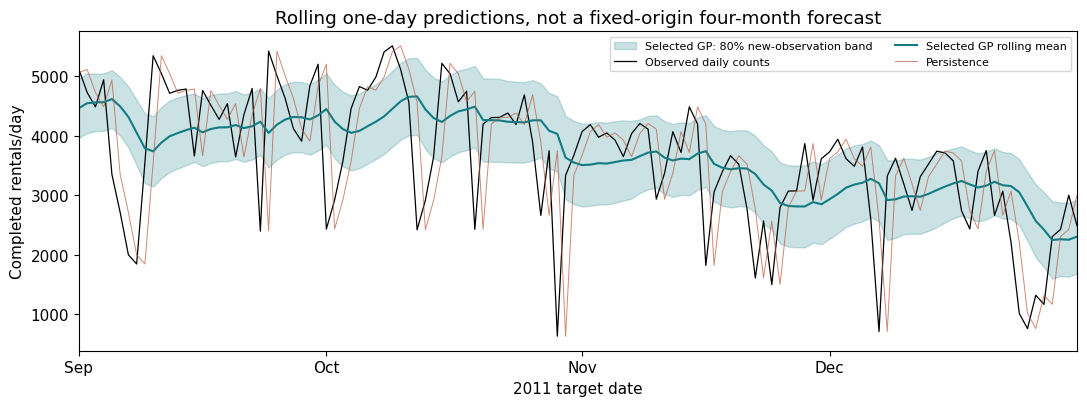

In [7]:
dates = bike.dteday.iloc[assessment_days]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(dates, selected[:, 0]-Z80*selected[:, 1], selected[:, 0]+Z80*selected[:, 1], color="#117c83", alpha=0.22, label="Selected GP: 80% new-observation band")
ax.plot(dates, y, color="black", linewidth=0.9, label="Observed daily counts")
ax.plot(dates, selected[:, 0], color="#117c83", linewidth=1.5, label="Selected GP rolling mean")
ax.plot(dates, predictions["Persistence"][:, 0], color="#bb573d", linewidth=0.7, alpha=0.7, label="Persistence")
ax.set(xlabel="2011 target date", ylabel="Completed rentals/day", title="Rolling one-day predictions, not a fixed-origin four-month forecast")
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b")); ax.set_xlim(dates.iloc[0], dates.iloc[-1]); ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); plt.show()

## 3. Score the quantity that matters
For common target dates, point errors give
$$\operatorname{MAE}=\frac1n\sum_t|C_t-\mu_t|,\qquad\operatorname{RMSE}=\sqrt{\frac1n\sum_t(C_t-\mu_t)^2}.$$
Squared error elicits a predictive mean, absolute error a median; the Gaussian proxy has the same mean and median. Different losses can rank these models differently on realized data. Lower is better for each loss below; coverage is compared with the nominal level, not maximized.

For $N(\mu_t,\sigma_t^2)$, negative log density is
$$\operatorname{NLL}_t=\tfrac12\log(2\pi)+\log\sigma_t+\frac{(C_t-\mu_t)^2}{2\sigma_t^2}.$$
This scores a **continuous density in the stated rental-count units**, not an exact discrete probability $P(C_t=c)$. Density scores change by an additive constant under a common unit conversion. A negative NLL can be valid for a density exceeding one; scores still require a common target, units, and reference measure.

For the prespecified event $C_t\ge4500$, $p_t=1-\Phi((4500-\mu_t)/\sigma_t)$ and $B_t=(p_t-\mathbf1\{C_t\ge4500\})^2$. The continuous proxy assigns no mass to equality; no continuity correction is silently applied. The Brier score evaluates this single event, not the full distribution.

With central 80% limits $L_t=\mu_t-z_{0.9}\sigma_t$ and $U_t=\mu_t+z_{0.9}\sigma_t$, report coverage, width, and
$$\operatorname{IS}_{0.2}=(U_t-L_t)+10(L_t-C_t)\mathbf1\{C_t<L_t\}+10(C_t-U_t)\mathbf1\{C_t>U_t\}.$$
NLL, Brier, and interval score are proper for their respective distribution/event/quantile targets in expectation. That does not guarantee that one finite dependent dataset recovers a true model. Very wide intervals can improve coverage while paying a width penalty.

In [8]:
def score(y, mean, sd, threshold=4500):
    y, mean, sd = np.asarray(y), np.asarray(mean), np.asarray(sd)
    if y.ndim != 1 or y.size == 0 or y.shape != mean.shape or y.shape != sd.shape:
        raise ValueError("Matched nonempty one-dimensional observations, means, and SDs required")
    if not all(np.isfinite(a).all() for a in [y, mean, sd, threshold]): raise ValueError("Finite score inputs required")
    if np.any(sd <= 0): raise ValueError("Predictive standard deviations must be positive")
    error = y-mean
    lower, upper = mean-Z80*sd, mean+Z80*sd
    probability = norm.sf((threshold-mean)/sd)
    interval = upper-lower+2/ALPHA*np.maximum(lower-y, 0)+2/ALPHA*np.maximum(y-upper, 0)
    return dict(MAE=np.mean(abs(error)), RMSE=np.sqrt(np.mean(error**2)),
        NLL=np.mean(0.5*np.log(2*np.pi)+np.log(sd)+0.5*(error/sd)**2),
        Brier=np.mean((probability-(y >= threshold))**2),
        coverage=np.mean((y >= lower)&(y <= upper)), width=np.mean(upper-lower),
        interval_score=np.mean(interval))

### Independent synthetic check
Use **one assigned observation** $y=2$ and the predictive law $N(0,1)$, with event threshold 1. This is a scoring fixture, not bike data. Then MAE=RMSE=2, NLL=$\tfrac12\log(2\pi)+2$, event probability $1-\Phi(1)$, Brier=$[1-\Phi(1)-1]^2$, coverage=0, width=$2z_{0.9}$, and interval score=$2z_{0.9}+10(2-z_{0.9})$. These hand values check signs, units, and out-of-interval penalties.

In [9]:
fixture = score([2.], [0.], [1.], threshold=1.)
expected = dict(MAE=2., RMSE=2., NLL=0.5*np.log(2*np.pi)+2,
    Brier=(norm.sf(1)-1)**2, coverage=0., width=2*Z80,
    interval_score=2*Z80+10*(2-Z80))
assert all(np.isclose(fixture[key], value) for key, value in expected.items())
display(pd.Series(fixture, name="Synthetic N(0,1), y=2, event threshold 1"))
print("PASS: hand normal scores and interval penalty")

MAE               2.000000
RMSE              2.000000
NLL               2.918939
Brier             0.707861
coverage          0.000000
width             2.563103
interval_score    9.747587
Name: Synthetic N(0,1), y=2, event threshold 1, dtype: float64

PASS: hand normal scores and interval penalty


In [10]:
scores = pd.DataFrame({name: score(y, *forecast.T) for name, forecast in predictions.items()}).T
scores.index.name = "Forecast method"
display(scores.round(6))
print("Selected method:", selected_label, "; other GP is a disclosed sensitivity comparator.")
print("Covered counts:", {name: int(round(row.coverage*len(y))) for name, row in scores.iterrows()})

,MAE,RMSE,NLL,Brier,coverage,width,interval_score
Forecast method,,,,,,,
GP length 14,741.297107,986.986264,9.065813,0.151425,0.590164,1335.161318,4129.546181
GP length 45,715.649780,952.753884,9.163776,0.148943,0.573770,1244.559679,3961.599011
Persistence,697.418033,982.418265,8.320978,0.119459,0.877049,2667.004898,3808.353152
Weekly lag 7,1048.737705,1401.648584,8.715594,0.192939,0.778689,3446.718660,5431.660162


Selected method: GP length 45 ; other GP is a disclosed sensitivity comparator.
Covered counts: {'GP length 14': 72, 'GP length 45': 70, 'Persistence': 107, 'Weekly lag 7': 95}


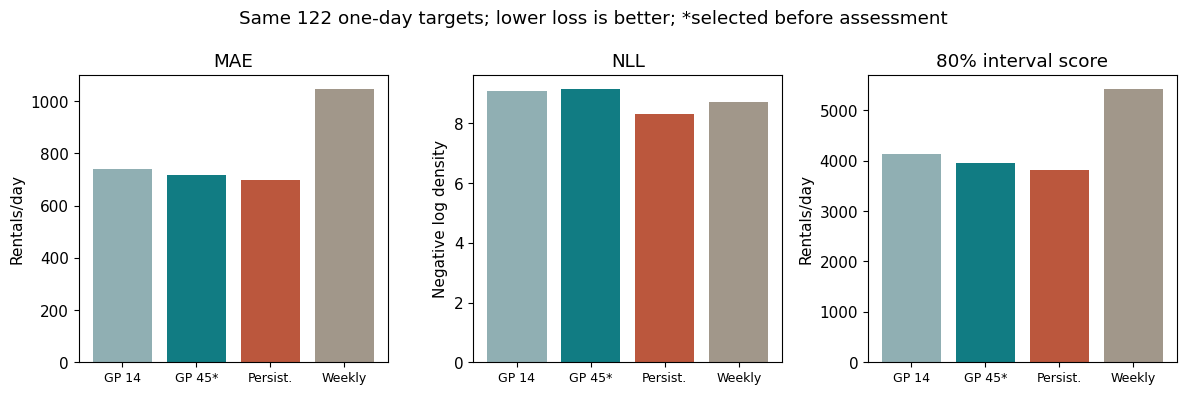

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
labels = ["GP 14", "GP 45*", "Persist.", "Weekly"]
for ax, metric in zip(axes, ["MAE", "NLL", "interval_score"]):
    ax.bar(labels, scores[metric], color=["#90afb3", "#117c83", "#bb573d", "#a1978a"])
    ax.set(title=metric.replace("interval_score", "80% interval score"), ylabel="Rentals/day" if metric != "NLL" else "Negative log density")
    ax.tick_params(axis="x", labelsize=9)
fig.suptitle("Same 122 one-day targets; lower loss is better; *selected before assessment")
fig.tight_layout(); plt.show()

The selected GP has **lower RMSE (952.75)** than persistence (982.42) but **higher MAE (715.65 versus 697.42)**. Its 80% band covers only **70/122 (57.4%)**, with mean width **1244.56** rentals/day; persistence covers **107/122 (87.7%)**, with width **2667.00**. A single best-model claim would hide the changed loss function and the GP’s narrow intervals. The declared selection loss remains MAE; a favorable assessment RMSE does not retroactively change it.

The weekly baseline is not guaranteed to win merely because weekly patterns are plausible. Compare errors and probabilistic scores on identical dates and forecast horizons, then inspect where the assumptions fail.

## 4. Diagnostic evidence is not an automatic pass/fail test
Standardized one-day errors are $r_t=(C_t-\mu_t)/\sigma_t$. Their scale and serial structure can reveal bias, underdispersion, or missing temporal variation. The probability integral transform is $u_t=F_t(C_t)=\Phi(r_t)$ under this continuous proxy. For an ideal continuously distributed outcome under its correct conditional predictive distribution, PIT values are uniform; time-series dependence and estimated/misspecified distributions complicate inference. The observed outcomes here are counts, so this unrandomized continuous-proxy PIT is a diagnostic, not an exact discrete calibration test.

Use descriptive plots without an iid p-value. Future observations may enter later predictions only after they have become available; that legitimate updating does not make assessment errors independent.

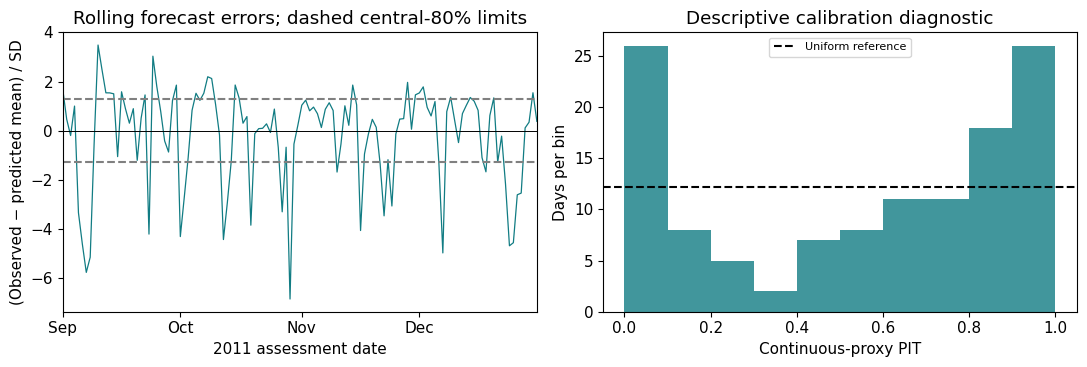

Standardized-error RMS and lag-1 correlation: 2.0313375328092342 0.4138452687887233


In [12]:
standardized = (y-selected[:, 0])/selected[:, 1]
pit = norm.cdf(standardized)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(dates, standardized, color="#117c83", linewidth=0.9)
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].axhline(Z80, color="gray", linestyle="--"); axes[0].axhline(-Z80, color="gray", linestyle="--")
axes[0].set(xlabel="2011 assessment date", ylabel="(Observed − predicted mean) / SD", title="Rolling forecast errors; dashed central-80% limits")
axes[0].set_xlim(dates.iloc[0], dates.iloc[-1]); axes[0].xaxis.set_major_locator(mdates.MonthLocator()); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[1].hist(pit, bins=np.linspace(0, 1, 11), color="#117c83", alpha=0.8)
axes[1].axhline(len(y)/10, color="black", linestyle="--", label="Uniform reference")
axes[1].set(xlabel="Continuous-proxy PIT", ylabel="Days per bin", title="Descriptive calibration diagnostic"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
print("Standardized-error RMS and lag-1 correlation:", np.sqrt(np.mean(standardized**2)), np.corrcoef(standardized[:-1], standardized[1:])[0, 1])

## 5. Sensitivity: change an assumption, preserve the comparison
Keep selected GP means fixed and replace predictive SD by $a\sigma_t$ for $a\in\{0.5,1,2\}$. MAE and RMSE cannot change; coverage, width, NLL, interval score, and event probabilities can. This is a **post-fit predictive-scale sensitivity analysis**, not refitting the GP observation-noise hyperparameter: changing that hyperparameter inside the covariance would generally change the mean too.

These factors are not candidates selected again using September–December. If a sensitivity result motivates a revision, name it as development and evaluate a frozen revision on newly reserved data later. Before running: can doubling width make an interval score worse even if coverage improves?

,SD_factor,MAE,RMSE,NLL,Brier,coverage,width,interval_score
0,0.5,715.64978,952.753884,14.660127,0.179874,0.278689,622.279840,5118.872671
1,1.0,715.64978,952.753884,9.163776,0.148943,0.573770,1244.559679,3961.599011
2,2.0,715.64978,952.753884,8.309548,0.138315,0.827869,2489.119359,3684.460523


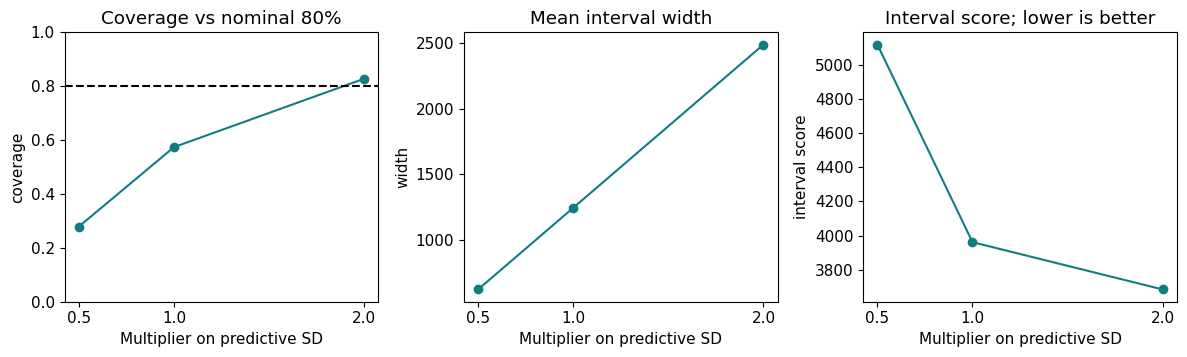

In [13]:
sensitivity = pd.DataFrame([dict(SD_factor=factor, **score(y, selected[:, 0], factor*selected[:, 1])) for factor in [0.5, 1., 2.]])
assert np.allclose(sensitivity.MAE, scores.loc[selected_label, "MAE"])
assert np.allclose(sensitivity.RMSE, scores.loc[selected_label, "RMSE"])
display(sensitivity.round(6))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, metric, title in zip(axes, ["coverage", "width", "interval_score"], ["Coverage vs nominal 80%", "Mean interval width", "Interval score; lower is better"]):
    ax.plot(sensitivity.SD_factor, sensitivity[metric], "o-", color="#117c83")
    ax.set(xlabel="Multiplier on predictive SD", ylabel=metric.replace("_", " "), title=title, xticks=[0.5, 1, 2])
axes[0].axhline(0.8, color="black", linestyle="--"); axes[0].set_ylim(0, 1)
fig.tight_layout(); plt.show()

### Deliberately invalid target leakage
For demonstration only, blend honest persistence with the outcome it is supposed to predict:
$$\widehat C_t^{\rm bad}=(1-w)C_{t-1}+wC_t,\qquad w\in\{0,0.5,1\}.$$
Its error is exactly $(1-w)(C_{t-1}-C_t)$, so both MAE and RMSE shrink by $1-w$. At $w=1$ the apparent forecast is perfect because it copies the target. This is **target leakage, not an improved forecasting method**. The target is unavailable at the stated origin; no score can rescue an invalid information set.

In [14]:
leakage_rows = []
for weight in [0., 0.5, 1.]:
    invalid = (1-weight)*predictions["Persistence"][:, 0]+weight*y
    error = invalid-y
    leakage_rows.append(dict(target_weight=weight, MAE=np.mean(abs(error)), RMSE=np.sqrt(np.mean(error**2))))
leakage = pd.DataFrame(leakage_rows)
assert np.allclose(leakage.RMSE, (1-leakage.target_weight)*scores.loc["Persistence", "RMSE"])
display(leakage)
print("INVALID forecast experiment: target outcomes are deliberately supplied to predictions.")

,target_weight,MAE,RMSE
0,0.0,697.418033,982.418265
1,0.5,348.709016,491.209133
2,1.0,0.000000,0.000000


INVALID forecast experiment: target outcomes are deliberately supplied to predictions.


## 6. Compare paired losses without pretending days are iid
Keep the date pairing and form
$$d_t=|C_t-\mu_t^{\rm GP}|-|C_t-C_{t-1}|,\qquad \bar d=\frac1n\sum_t d_t.$$
Positive $\bar d$ favors persistence on MAE; negative favors the selected GP. Resample the **differences** so both models continue to share each target day. Separate resampling of the two loss series destroys their pairing.

For a moving-block bootstrap, sample contiguous blocks of length $L$ uniformly from starts $0,\ldots,n-L$, concatenate $\lceil n/L\rceil$ sampled blocks and truncate to $n$. Use 2000 resamples, seed 6231, and the 2.5% and 97.5% percentiles of resampled means. Blocks do not wrap around December to September. $L=1$ is ordinary iid resampling; compare $L=7$ and 14 as dependence sensitivity, not as a search for significance.

The resulting interval is an **approximate descriptive uncertainty summary conditional on this period, fitted forecasts, and selection**. Its usual repeated-sampling motivation requires suitable weak dependence and approximate stationarity; trends or disruptions threaten that justification. It ignores model-selection uncertainty and is not a causal effect, a guarantee of future advantage, or a proof of model equivalence when it includes zero. Noncircular edge weighting can shift the bootstrap center; we report the observed mean separately.

In [15]:
def block_bootstrap(values, length=7, replicas=2000, seed=SEED):
    values = np.asarray(values, float)
    n = len(values)
    if not 1 <= length <= n: raise ValueError("Block length must be from 1 to sample size")
    rng = np.random.default_rng(seed)
    starts = rng.integers(0, n-length+1, size=(replicas, int(np.ceil(n/length))))
    indices = (starts[:, :, None]+np.arange(length)).reshape(replicas, -1)[:, :n]
    return values[indices].mean(axis=1)
difference = abs(y-selected[:, 0])-abs(y-predictions["Persistence"][:, 0])
bootstrap = {length: block_bootstrap(difference, length) for length in [1, 7, 14]}
intervals = pd.DataFrame([dict(block_days=length, observed_mean=difference.mean(),
    lower=np.quantile(draws, 0.025), upper=np.quantile(draws, 0.975)) for length, draws in bootstrap.items()])
display(intervals)

,block_days,observed_mean,lower,upper
0,1,18.231747,-103.503783,142.494476
1,7,18.231747,-101.830090,145.644807
2,14,18.231747,-118.098926,108.575989


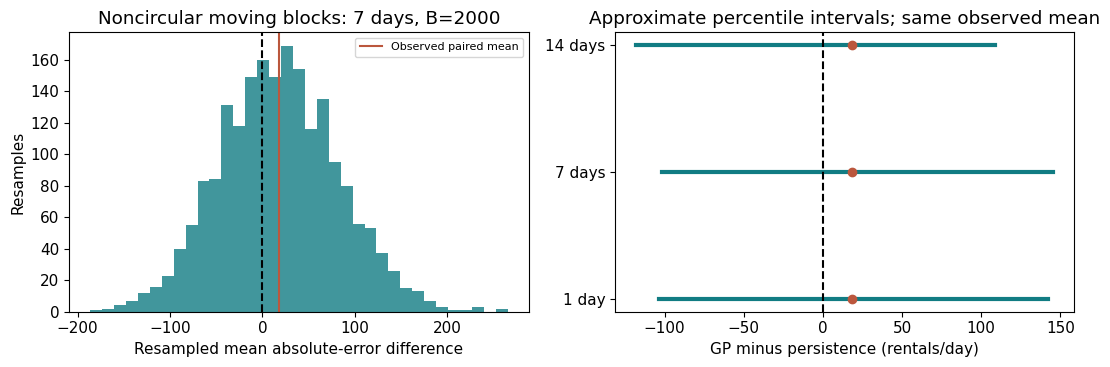

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(bootstrap[7], bins=35, color="#117c83", alpha=0.8)
axes[0].axvline(difference.mean(), color="#bb573d", label="Observed paired mean")
axes[0].axvline(0, color="black", linestyle="--"); axes[0].legend(fontsize=8)
axes[0].set(xlabel="Resampled mean absolute-error difference", ylabel="Resamples", title="Noncircular moving blocks: 7 days, B=2000")
for row, item in intervals.iterrows():
    axes[1].plot([item.lower, item.upper], [row, row], color="#117c83", linewidth=3)
    axes[1].plot(item.observed_mean, row, "o", color="#bb573d")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set(yticks=range(3), yticklabels=["1 day", "7 days", "14 days"], xlabel="GP minus persistence (rentals/day)", title="Approximate percentile intervals; same observed mean")
fig.tight_layout(); plt.show()

The observed difference is **+18.23 rentals/day**, so persistence has slightly smaller MAE on these dates. The default 7-day percentile interval is approximately **[−101.83, 145.64]**, and all three displayed intervals include zero. This does not establish equal forecasting quality: it indicates that these conditional summaries do not isolate a stable sign of advantage. The 14-day interval has a shifted center because noncircular resampling gives edge dates different weights; block length is an assumption worth reporting.

NumPy and the browser use different random generators, so bootstrap endpoints need not match draw-for-draw. They should agree on the observed paired difference and implement the same resampling scheme. Seed replay should reproduce a given implementation.

## 7. Verification, optional AI repair, and a frozen project plan
Use two independent forms of evidence: a hand synthetic score plus a prefix-information test, or exact leakage algebra plus a separately reconstructed rolling baseline. Asking an AI to approve its own result is not independent verification. AI use is optional and needs no paid account; disclose consequential assistance and retained corrections.

A deliberately flawed proposal appears below. Repair its selection protocol, residual scale, event probability, date pairing, and dependence claim:
```python
# Deliberately flawed; do not execute.
best = min(candidates, key=lambda m: mae(y_sep_dec, m))
scale = np.std(all_errors)  # includes future errors
p_event = norm.pdf(4500, loc=mu, scale=sd)
difference = np.abs(error_gp) - np.abs(rng.permutation(error_base))
# Call an iid bootstrap interval guaranteed evidence of future superiority.
```

For the existing project, record before a future final evaluation: prediction target and units; forecast origin and horizon; available features; training/selection/final dates; update policy; one primary loss; point and probabilistic baselines; sensitivity scenarios; and what information would trigger a new development cycle. Once final outcomes influence a revision, reserve new data for another final claim.

In [17]:
changed = counts.copy(); changed[260] += 10000  # An outcome not known before day 260 ends.
assert np.allclose(issue_gp(changed, np.arange(243, 261), selected_ell), selected[:18])
assert not np.isclose(gp_forecast(changed[:261], selected_ell)[0], gp_forecast(counts[:261], selected_ell)[0])
for lag in [1, 7]:
    assert np.allclose(issue_baseline(changed, np.arange(243, 261), lag), issue_baseline(counts, np.arange(243, 261), lag))
assert np.array_equal(block_bootstrap(difference, 7), bootstrap[7])
assert np.allclose(block_bootstrap(np.ones(12)*3, 7), 3)
assert np.isclose(difference.mean(), scores.loc[selected_label, "MAE"]-scores.loc["Persistence", "MAE"])
print("PASS: future-outcome invariance, legitimate next-origin update, seed replay, constant-loss fixture, pairing")
print("Runtime:", platform.python_version(), {p: metadata.version(p) for p in ["numpy", "pandas", "scipy", "matplotlib"]})

PASS: future-outcome invariance, legitimate next-origin update, seed replay, constant-loss fixture, pairing


Runtime: 3.10.9 {'numpy': '1.24.2', 'pandas': '2.0.0', 'scipy': '1.10.1', 'matplotlib': '3.7.1'}


## 8. Four investigations · your work
The following cells remain unanswered in the distributed notebook. Submit these concise investigations together with Module 11 as **one Concept Lab 6 submission due in week 12**. Reuse the worked calculations; do not create another large project.

### E1 — Freeze the information set
Reproduce July–August selection between the two GP length scales using one-day MAE, then assess the frozen choice on September–December with rolling updates from earlier observations only. Compare persistence and weekly lag-seven forecasts on the same dates. Change a future count and verify that predictions issued before observing it stay unchanged; distinguish this protocol from Module 11’s fixed-origin forecast.

In [18]:
# YOUR WORK — E1
# Add your calculation and a short interpretation here.

### E2 — Score the prediction target
Report MAE, RMSE, Gaussian negative log density, Brier score for a count at least 4500, central 80% coverage, mean width, and interval score for the four stated methods on the 122 assessment dates. Check the scores by hand for one normal predictive distribution and one observed value. Explain why coverage alone, training error, or a continuous density treated as a count probability can mislead.

In [19]:
# YOUR WORK — E2
# Add your calculation and a short interpretation here.

### E3 — Audit sensitivity and leakage
Multiply the selected GP’s predictive standard deviations by 0.5, 1, and 2 without changing its means; compare point errors, coverage, width, and proper scores. Apply the deliberately invalid target blend with weights 0, 0.5, and 1 to persistence. Explain the apparent improvement, identify information unavailable at the origin, and state which comparisons are sensitivity analyses rather than new model selections.

In [20]:
# YOUR WORK — E3
# Add your calculation and a short interpretation here.

### E4 — Compare paired losses under dependence
Form daily absolute-error differences (selected GP minus persistence). Use 2000 moving-block resamples with block lengths 1, 7, and 14 and seed 6231; report the observed mean and percentile intervals. Explain pairing, the sign convention, block-length sensitivity, and stationarity/selection limitations. Repair the AI-style code with two independent checks, draft a frozen final-evaluation plan for the existing project, and disclose optional AI assistance.

In [21]:
# YOUR WORK — E4
# Add your calculation and a short interpretation here.

## 9. Optional extension and next step
Use several prespecified rolling selection folds entirely before a reserved final period, or compare a count predictive distribution using genuine discrete log probabilities. Account for estimation/selection if developing a more formal uncertainty statement. These are optional extensions, not new assignments.

[Module 13](../modules/module13.html) develops project refinement, reproducibility, and AI-output verification. Carry the declared comparison protocol, one uncertainty check, and one sensitivity conclusion into the existing project.

References: the supplied MATH 6241 notes supply the process-model context; validation and scoring are applied additions. Rasmussen and Williams (2006), [Gaussian Processes for Machine Learning, Chapter 2](https://gaussianprocess.org/gpml/chapters/RW2.pdf), gives Gaussian conditioning. Gneiting and Raftery (2007), [Strictly Proper Scoring Rules, Prediction, and Estimation](https://doi.org/10.1198/016214506000001437), develops proper scores. Künsch (1989), [The Jackknife and the Bootstrap for General Stationary Observations](https://doi.org/10.1214/aos/1176347265), provides the dependent-data bootstrap context.

Temporal evaluation: Hyndman and Athanasopoulos, [Forecasting: Principles and Practice, time-series cross-validation](https://otexts.com/fpp3/toolbox.html#time-series-cross-validation). Moving-block construction and limitations: Shalizi, [Simulation for Inference I — The Bootstrap](https://www.stat.cmu.edu/~cshalizi/dst/20/lectures/16/lecture-16.html). The Künsch citation is historical context; the inspected teaching explanation is Shalizi’s lecture.